In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
df= pd.read_csv("data_cancer.csv")

In [2]:
df.head()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.tail()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
564,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,0.05623,...,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115,0
565,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,0.05533,...,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637,0
566,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,0.05648,...,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820,0
567,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,0.2397,0.07016,...,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400,0
568,7.76,24.54,47.92,181.0,0.05263,0.04362,0.00000,0.00000,0.1587,0.05884,...,30.37,59.16,268.6,0.08996,0.06444,0.0000,0.0000,0.2871,0.07039,1


In [4]:
df.shape

(569, 31)

In [5]:
# Information about the data types and non-null values
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean_radius              569 non-null    float64
 1   mean_texture             569 non-null    float64
 2   mean_perimeter           569 non-null    float64
 3   mean_area                569 non-null    float64
 4   mean_smoothness          569 non-null    float64
 5   mean_compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

In [6]:
# Missing values
df.isnull().sum()

mean_radius                0
mean_texture               0
mean_perimeter             0
mean_area                  0
mean_smoothness            0
mean_compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
diagnosis                  0
dtype: int64

In [7]:
df.duplicated().sum()

0

In [8]:
df.describe()

,mean_radius,mean_texture,mean_perimeter,mean_area,mean_smoothness,mean_compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


In [9]:
# Target variable: 0 = malignant, 1 = benign 
df["diagnosis"].value_counts()

diagnosis
1    357
0    212
Name: count, dtype: int64

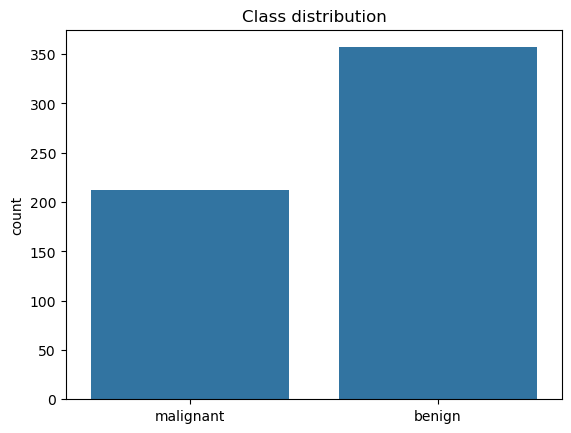

In [10]:
sns.countplot(x = df["diagnosis"].map({0: "malignant", 1: "benign"}))
plt.title("Class distribution")
plt.xlabel("")
plt.show()

In [11]:
feature_cols = [c for c in df.columns if c != "diagnosis"]
X = df[feature_cols]
y = df["diagnosis"]
X.shape, y.shape

((569, 30), (569,))

In [12]:
# Import the libraries for the models and the evaluation
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
from sklearn.pipeline import Pipeline
import warnings
warnings.filterwarnings("ignore")

In [13]:
models = {"kNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))]),
    "Random Forest": Pipeline([
        ("scaler", StandardScaler()),
        ("model", RandomForestClassifier(random_state=42))])}
train_sizes = [0.05, 0.15, 0.25]
records = []

for ts in train_sizes:
    for seed in range(10):
        X_train, X_test, y_train, y_test = train_test_split(
            X, y, train_size = ts, stratify=y, random_state = seed)    

        for name, model in models.items():
            cv_scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy", n_jobs=1) 
            model.fit(X_train, y_train)
            records.append({
                "train_size": ts,
                "seed": seed,
                "model": name,
                "cv_acc": cv_scores.mean(),
                "train_acc": model.score(X_train, y_train),
                "test_acc": model.score(X_test, y_test),})

res = pd.DataFrame(records)
summary = res.groupby(["train_size", "model"])[["cv_acc", "train_acc", "test_acc"]].agg(["mean", "std"])
print(summary.round(4))

  File "C:\Users\sa_dy\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\sa_dy\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\sa_dy\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\sa_dy\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(executable, args,
                       ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^


                          cv_acc         train_acc         test_acc        
                            mean     std      mean     std     mean     std
train_size model                                                           
0.05       Random Forest  0.9293  0.0373    1.0000  0.0000   0.9152  0.0148
           kNN            0.8853  0.0641    0.9357  0.0499   0.9311  0.0128
0.15       Random Forest  0.9353  0.0329    1.0000  0.0000   0.9421  0.0134
           kNN            0.9424  0.0296    0.9753  0.0196   0.9473  0.0097
0.25       Random Forest  0.9451  0.0160    1.0000  0.0000   0.9461  0.0115
           kNN            0.9527  0.0192    0.9676  0.0185   0.9518  0.0050


In [14]:
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.25, stratify=y, random_state=42)

In [15]:
knn_pipeline = Pipeline([("scaler", StandardScaler()),("model", KNeighborsClassifier())])

rf_pipeline = Pipeline([("scaler", StandardScaler()),("model", RandomForestClassifier(random_state=42))])

knn_grid = GridSearchCV(knn_pipeline, param_grid={"model__n_neighbors": [3, 5, 7, 9, 11], "model__weights": ["uniform", "distance"], "model__metric": ["euclidean", "manhattan"]}, cv=5, scoring="accuracy", n_jobs=1)
knn_grid.fit(X_train, y_train)
rf_grid = GridSearchCV(rf_pipeline, param_grid={"model__n_estimators": [100, 200], "model__max_depth": [None, 5, 10], "model__min_samples_split": [2, 5]}, cv=5, scoring="accuracy",n_jobs=1)

rf_grid.fit(X_train, y_train)

print("Best KNN parameters:", knn_grid.best_params_)
print("Best KNN accuracy:", knn_grid.best_score_)

print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best Random Forest accuracy:", rf_grid.best_score_)

Best KNN parameters: {'model__metric': 'euclidean', 'model__n_neighbors': 3, 'model__weights': 'uniform'}
Best KNN accuracy: 0.9721674876847292
Best Random Forest parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Best Random Forest accuracy: 0.9652709359605911


In [16]:
for label, grid in [("kNN (tuned)", knn_grid), ("Random Forest (tuned)", rf_grid)]:
    y_pred = grid.predict(X_test)
    print(f"\n--- {label} ---")
    print("Best parameters:", grid.best_params_)
    print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print("Confusion matrix:\n", confusion_matrix(y_test, y_pred))
    print("Classification report:\n", classification_report(y_test, y_pred, digits=4))


--- kNN (tuned) ---
Best parameters: {'model__metric': 'euclidean', 'model__n_neighbors': 3, 'model__weights': 'uniform'}
Test accuracy: 0.9391
Confusion matrix:
 [[134  25]
 [  1 267]]
Classification report:
               precision    recall  f1-score   support

           0     0.9926    0.8428    0.9116       159
           1     0.9144    0.9963    0.9536       268

    accuracy                         0.9391       427
   macro avg     0.9535    0.9195    0.9326       427
weighted avg     0.9435    0.9391    0.9379       427


--- Random Forest (tuned) ---
Best parameters: {'model__max_depth': None, 'model__min_samples_split': 2, 'model__n_estimators': 100}
Test accuracy: 0.9438
Confusion matrix:
 [[139  20]
 [  4 264]]
Classification report:
               precision    recall  f1-score   support

           0     0.9720    0.8742    0.9205       159
           1     0.9296    0.9851    0.9565       268

    accuracy                         0.9438       427
   macro avg     0.950

In [17]:
rf_best = rf_grid.best_estimator_
feature_importances = pd.Series(rf_best.named_steps["model"].feature_importances_,index=X.columns).sort_values(ascending=False)
print("\nTop 10 most important features (Random Forest):\n", feature_importances.head(10).round(4))


Top 10 most important features (Random Forest):
 worst concave points    0.1833
worst area              0.1325
worst perimeter         0.0964
mean_perimeter          0.0950
mean concave points     0.0803
mean concavity          0.0699
worst radius            0.0613
mean_radius             0.0567
worst concavity         0.0437
mean_area               0.0341
dtype: float64


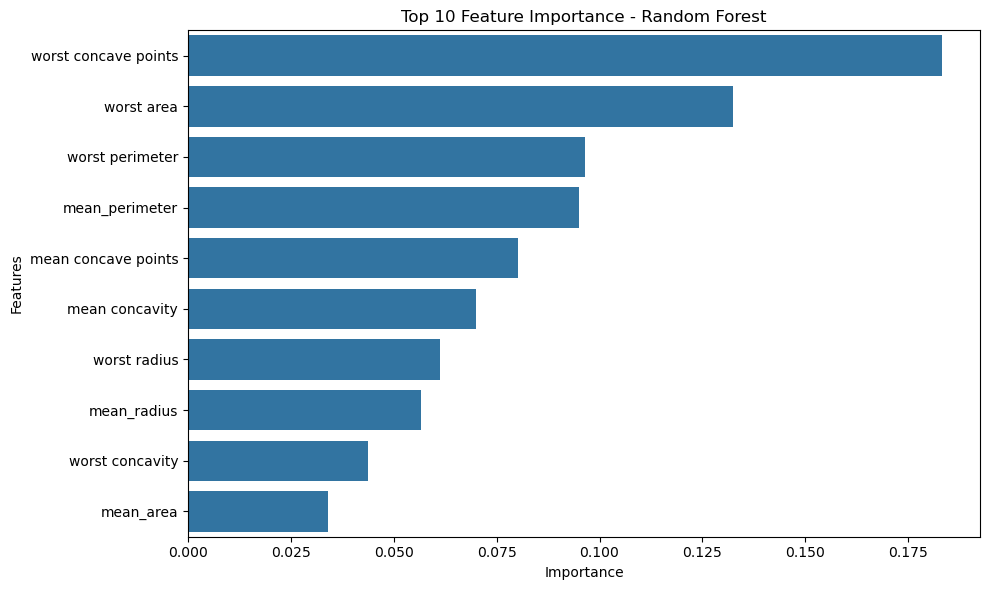

In [18]:
plt.figure(figsize=(10, 6))
sns.barplot(x = feature_importances.head(10).values, y = feature_importances.head(10).index)
plt.title("Top 10 Feature Importance - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

__Comparison of Test Accuracy Across Training Sizes__

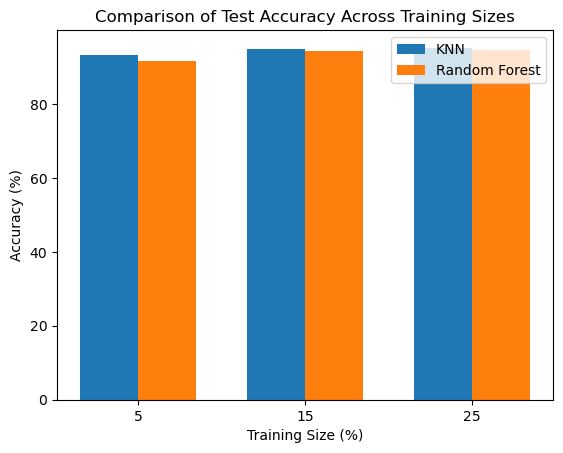

In [19]:
# Data
training_sizes = [5, 15, 25]
knn_accuracy = [93.11, 94.73, 95.18]
rf_accuracy = [91.52, 94.21, 94.61]

x = np.arange(len(training_sizes))
width = 0.35
plt.bar(x - width/2, knn_accuracy, width, label="KNN")
plt.bar(x + width/2, rf_accuracy, width, label="Random Forest")
plt.xlabel("Training Size (%)")
plt.ylabel("Accuracy (%)")
plt.title("Comparison of Test Accuracy Across Training Sizes")
plt.xticks(x, training_sizes)
plt.legend()
plt.show()

__Comparison of Cross-validation Accuracy Across Training Sizes__

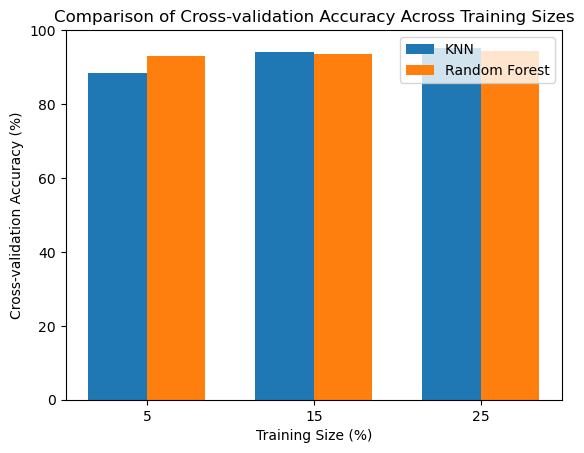

In [20]:
# Cross-validation accuracy data
training_sizes = [5, 15, 25]
knn_cv = [88.53, 94.24, 95.27]
rf_cv = [92.93, 93.53, 94.51]
x = np.arange(len(training_sizes))
width = 0.35
plt.bar(x - width/2, knn_cv, width, label="KNN")
plt.bar(x + width/2, rf_cv, width, label="Random Forest")
plt.xlabel("Training Size (%)")
plt.ylabel("Cross-validation Accuracy (%)")
plt.title("Comparison of Cross-validation Accuracy Across Training Sizes")
plt.xticks(x, training_sizes)
plt.legend()
plt.show()

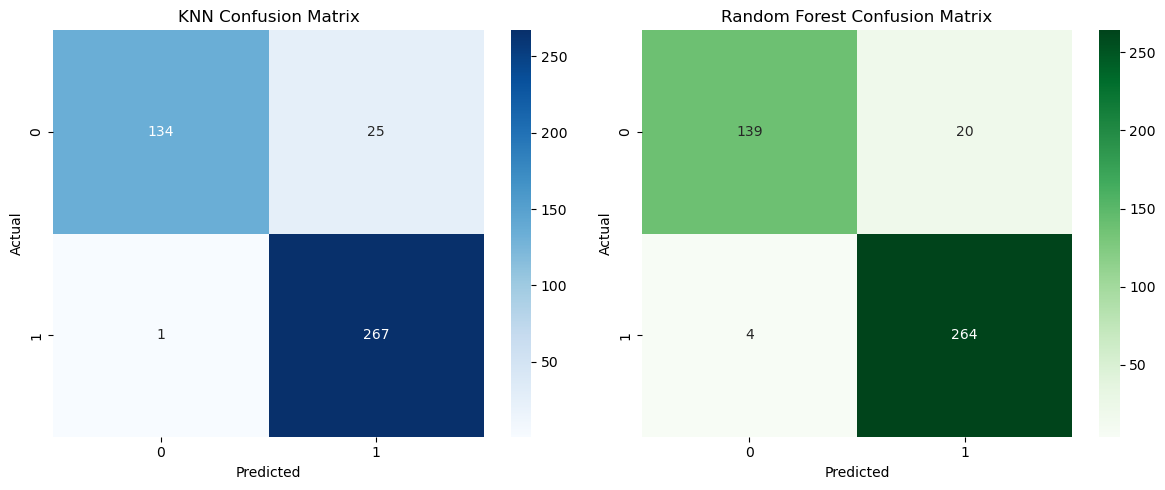

In [21]:
# Confusion matrices
knn_cm = [[134, 25], [1, 267]]
rf_cm = [[139, 20], [4, 264]]

# Create two plots
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# KNN heatmap
sns.heatmap(knn_cm, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("KNN Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

# Random Forest heatmap
sns.heatmap(rf_cm, annot=True, fmt="d", cmap="Greens", ax=axes[1])
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()